# Exercise 28 – Simulated annealing in a box

**Week 5 · Molecular dynamics**

Ten mobile atoms are enclosed by a square "wall" of 20 fixed atoms. Starting
hot and cooling slowly – *simulated annealing* – lets the atoms explore many
configurations before they settle; this often finds lower-energy structures
than relaxing directly from the start.

The temperature is lowered linearly from $k_BT = 5$ to $0.01$ over 1500
thermostat segments of 50 velocity-Verlet steps.

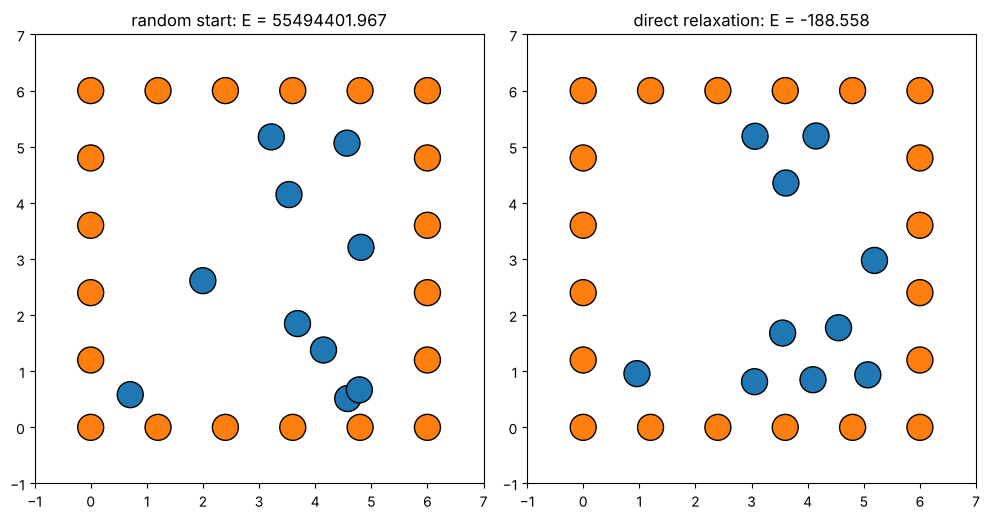

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image
from matplotlib.animation import FuncAnimation, PillowWriter

from comphy import ROOT_DIR
from comphy.atoms import Cluster, LennardJones, line_search_relax
from comphy.md import kinetic_energy, thermostatted_md

rng = np.random.default_rng(0)
calc = LennardJones()

side = np.linspace(0, 6, 6)
grid = np.array([(x, y) for x in side for y in side])
wall = grid[(grid[:, 0] == 0) | (grid[:, 0] == 6) | (grid[:, 1] == 0) | (grid[:, 1] == 6)]
mobile = rng.uniform(0.5, 5.5, (10, 2))
start = Cluster(calc, np.vstack([wall, mobile]), static=[True] * len(wall) + [False] * 10)

relaxed = start.copy()
line_search_relax(relaxed)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, c, title in [(axes[0], start, "random start"), (axes[1], relaxed, "direct relaxation")]:
    c.draw(ax, size=350)
    ax.set(xlim=(-1, 7), ylim=(-1, 7))
    ax.set_title(f"{title}: {ax.get_title()}")
fig.tight_layout()
plt.show()

## Annealing

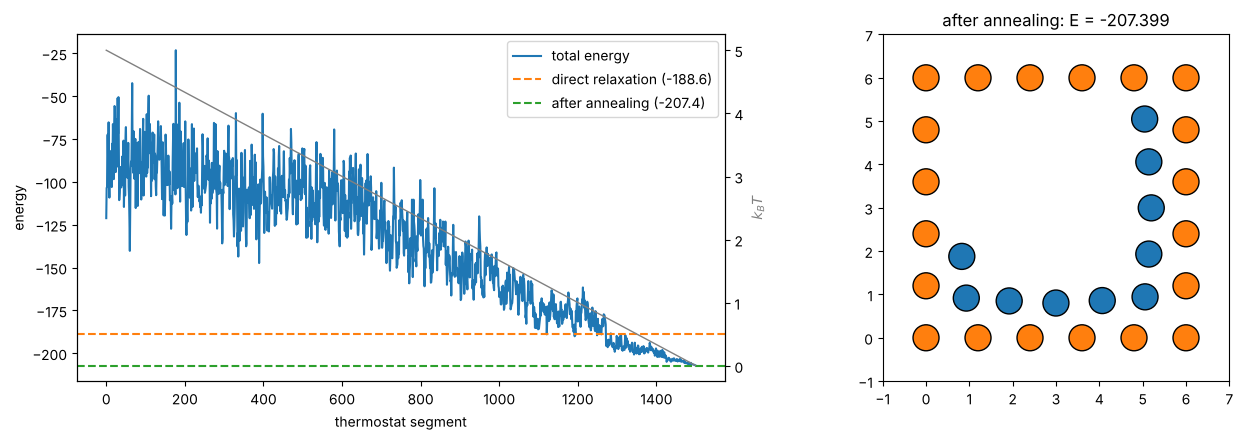

In [2]:
n_segments = 1500
schedule = np.linspace(5.0, 0.01, n_segments)
xs, vs = thermostatted_md(relaxed.positions, calc.forces, schedule, n_segments=n_segments,
                          steps_per_segment=50, dt=0.01, fixed=relaxed.static, rng=rng)
energies = np.array([calc.energy(x) + kinetic_energy(v) for x, v in zip(xs, vs)])

annealed = Cluster(calc, xs[-1], relaxed.static)
line_search_relax(annealed)            # remove the last bit of thermal motion

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(energies, label="total energy")
axes[0].axhline(relaxed.energy, color="C1", ls="--", label=f"direct relaxation ({relaxed.energy:.1f})")
axes[0].axhline(annealed.energy, color="C2", ls="--", label=f"after annealing ({annealed.energy:.1f})")
axes[0].set(xlabel="thermostat segment", ylabel="energy")
axes[0].legend()
ax2 = axes[0].twinx()
ax2.plot(schedule, color="gray", lw=1)
ax2.set_ylabel("$k_BT$", color="gray")
annealed.draw(axes[1], size=350)
axes[1].set(xlim=(-1, 7), ylim=(-1, 7))
axes[1].set_title(f"after annealing: {axes[1].get_title()}")
fig.tight_layout()
plt.show()

## Animation of the annealing run

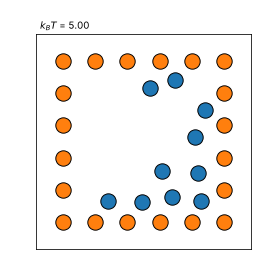

In [3]:
gif = ROOT_DIR / "figures" / "ex28_simulated_annealing.gif"
gif.parent.mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(4, 4), dpi=70)
ax.scatter(*wall.T, s=250, c="C1", edgecolor="black")
atoms = ax.scatter(*xs[0][~relaxed.static].T, s=250, c="C0", edgecolor="black")
label = ax.text(0.02, 1.02, "", transform=ax.transAxes)
ax.set(xlim=(-1, 7), ylim=(-1, 7), aspect="equal", xticks=[], yticks=[])


def update(i):
    atoms.set_offsets(xs[i][~relaxed.static])
    label.set_text(f"$k_BT$ = {schedule[i]:.2f}")


anim = FuncAnimation(fig, update, frames=range(0, n_segments, 10))
anim.save(gif, writer=PillowWriter(fps=20))
plt.close(fig)
Image(filename=gif)